# Evaluación 2: comparación CNN y MLP para Sign Language MNIST

**Variante:** diez clases ASL `A, B, C, D, E, I, L, M, N, O` (etiquetas originales `0, 1, 2, 3, 4, 8, 11, 12, 13, 14`). Semilla: `42069`.

Este notebook compara un MLP de una capa oculta (la arquitectura pequeña elegida en la Evaluación 1) con una CNN sobre las mismas imágenes y la misma partición. Se entrenan ambos modelos con el mismo optimizador, pérdida, número de épocas, tamaño de lote y datos de validación. El conjunto de prueba queda reservado para la evaluación final.


## 1. Preparación de datos

Se filtran las mismas diez clases y se remapean a etiquetas consecutivas. Los píxeles se normalizan a `[0,1]`; ambas redes reciben las mismas muestras de entrenamiento y validación estratificadas (80/20, semilla `42069`) y se evalúan en el mismo conjunto de prueba oficial filtrado. El MLP aplana las imágenes dentro de su arquitectura; la CNN conserva el formato espacial `(28,28,1)`.


In [ ]:
import os, time
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42069
np.random.seed(SEED)
tf.random.set_seed(SEED)
LABEL_MAP = {0:'A', 1:'B', 2:'C', 3:'D', 4:'E', 8:'I', 11:'L', 12:'M', 13:'N', 14:'O'}
ORIGINAL_LABELS = list(LABEL_MAP)
CLASS_NAMES = list(LABEL_MAP.values())
REMAP = {label:i for i,label in enumerate(ORIGINAL_LABELS)}
train_path = 'sign_mnist_train.csv'
test_path = 'sign_mnist_test.csv'
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
train_part = train_df[train_df.label.isin(ORIGINAL_LABELS)].copy()
test_part = test_df[test_df.label.isin(ORIGINAL_LABELS)].copy()
y_all = train_part.label.map(REMAP).to_numpy()
y_test = test_part.label.map(REMAP).to_numpy()
X_all = train_part.iloc[:, 1:].to_numpy(dtype=np.float32).reshape(-1,28,28,1) / 255.0
X_test = test_part.iloc[:, 1:].to_numpy(dtype=np.float32).reshape(-1,28,28,1) / 255.0
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.20, random_state=SEED, stratify=y_all
)
print('TensorFlow:', tf.__version__)
print('Train:', X_train.shape, 'Validación:', X_val.shape, 'Prueba:', X_test.shape)
print('Rango de píxeles:', float(X_train.min()), 'a', float(X_train.max()))


TensorFlow: 2.21.0
Train: (8990, 28, 28, 1) Validación: (2248, 28, 28, 1) Prueba: (3244, 28, 28, 1)
Rango de píxeles: 0.0 a 1.0


## 2. Arquitecturas comparadas

El MLP de control replica la arquitectura pequeña seleccionada en la Evaluación 1: `Flatten → Dense(128, ReLU) → Dense(10, Softmax)`. La CNN sigue la arquitectura convolucional inicial del notebook de clases: `Conv2D(32, 3×3, ReLU) → MaxPooling2D(2×2) → Flatten → Dense(128, ReLU) → Dense(10, Softmax)`. Ambas usan Adam (`learning_rate=0.001`) y `sparse_categorical_crossentropy`.

Se omiten las capas de regularización y el aumento de datos. No se realiza búsqueda de hiperparámetros: se comparan estas dos arquitecturas con condiciones de entrenamiento iguales.


In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.optimizers import Adam

mlp_model = Sequential([
    Input(shape=(28,28,1), name='imagen_28x28'),
    Flatten(name='aplanado'),
    Dense(128, activation='relu', name='oculta_128'),
    Dense(10, activation='softmax', name='salida_10_clases')
], name='MLP_control_E1')

model = Sequential([
    Input(shape=(28,28,1), name='imagen_28x28'),
    Conv2D(32, (3,3), activation='relu', name='conv_1'),
    MaxPooling2D((2,2), name='pool_1'),
    Flatten(name='aplanado'),
    Dense(128, activation='relu', name='densa_128'),
    Dense(10, activation='softmax', name='salida_10_clases')
], name='CNN_inicial')

for candidate in (mlp_model, model):
    candidate.compile(optimizer=Adam(learning_rate=0.001),
                      loss='sparse_categorical_crossentropy', metrics=['accuracy'])

mlp_params = mlp_model.count_params()
cnn_params = model.count_params()
print('Parámetros MLP:', f'{mlp_params:,}')
print('Parámetros CNN:', f'{cnn_params:,}')
mlp_model.summary()
model.summary()


Parámetros MLP: 101,770
Parámetros CNN: 693,962


Model: "MLP_control_E1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aplanado (Flatten)              │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_128 (Dense)              │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_10_clases (Dense)        │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

...

Model: "CNN_inicial"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aplanado (Flatten)              │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_128 (Dense)               │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_10_clases (Dense)        │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Entrenamiento bajo las mismas condiciones

Como en el notebook de referencia, los dos modelos se entrenan con Adam durante un número fijo de épocas y batch size 64, registrando accuracy y pérdida en entrenamiento y validación. Ambos reciben el mismo conjunto de datos y validación. Se mantiene aparte el test para no usarlo durante el ajuste.


Epoch 1/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4699 - loss: 1.6939 - val_accuracy: 0.6481 - val_loss: 1.1933
Epoch 2/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7504 - loss: 0.9496 - val_accuracy: 0.8087 - val_loss: 0.7713
Epoch 3/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8463 - loss: 0.6401 - val_accuracy: 0.8585 - val_loss: 0.5641
Epoch 4/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8974 - loss: 0.4707 - val_accuracy: 0.8990 - val_loss: 0.4274
Epoch 5/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9257 - loss: 0.3630 - val_accuracy: 0.9382 - val_loss: 0.3273
Epoch 6/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9433 - loss: 0.2893 - val_accuracy: 0.9626 - val_loss: 0.2557
Epoch 7/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9544 - loss: 0.2367 - val_accuracy: 0.9684 - val_loss: 0.2045
Epoch 8/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9624 - loss: 0.1979 - val_accuracy: 0.

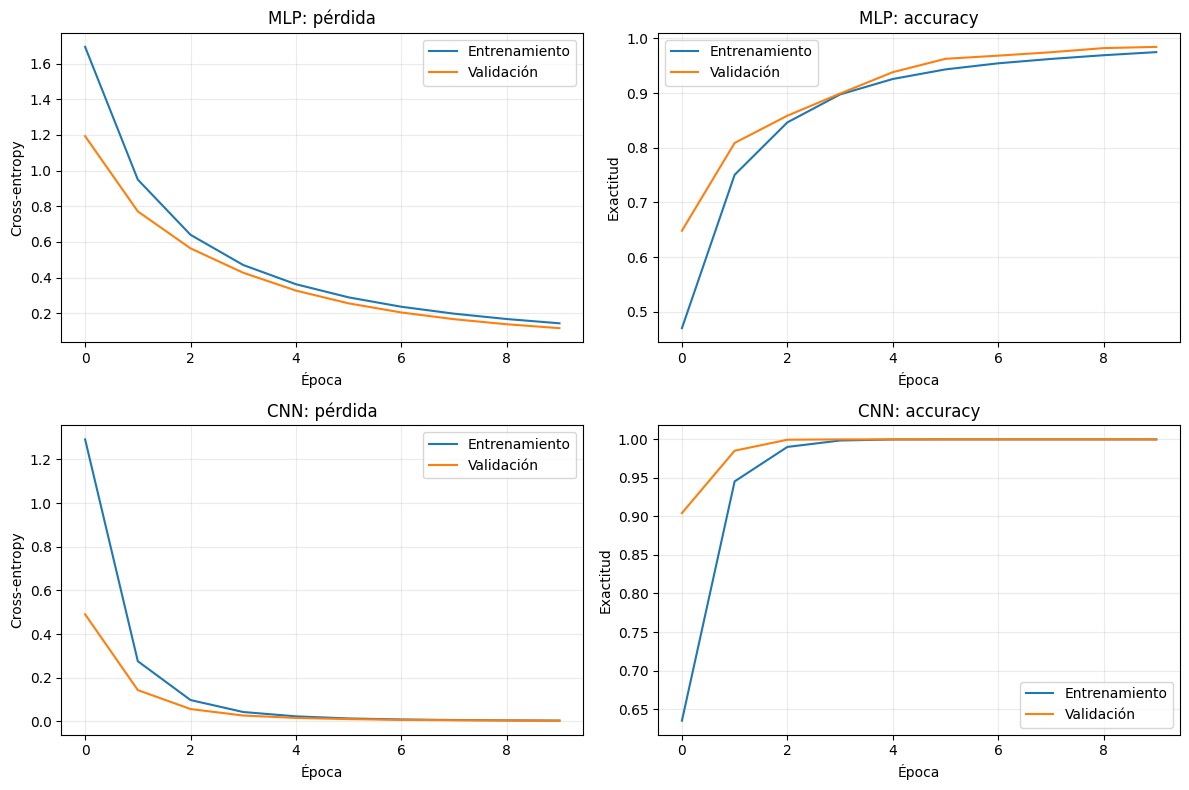

Tiempo MLP: 7.23 s | CNN: 54.72 s


In [ ]:
EPOCHS = 10
BATCH_SIZE = 64

# Asegurar que el directorio de salida existe
os.makedirs('outputs', exist_ok=True)

start = time.perf_counter()
history_mlp = mlp_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                            epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1)
mlp_train_seconds = time.perf_counter() - start

start = time.perf_counter()
history_cnn = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=1)
cnn_train_seconds = time.perf_counter() - start

fig, axes = plt.subplots(2,2,figsize=(12,8))
for row, (name, hist) in enumerate([('MLP', history_mlp), ('CNN', history_cnn)]):
    axes[row,0].plot(hist.history['loss'], label='Entrenamiento')
    axes[row,0].plot(hist.history['val_loss'], label='Validación')
    axes[row,0].set(title=f'{name}: pérdida', xlabel='Época', ylabel='Cross-entropy')
    axes[row,0].legend(); axes[row,0].grid(alpha=.25)
    axes[row,1].plot(hist.history['accuracy'], label='Entrenamiento')
    axes[row,1].plot(hist.history['val_accuracy'], label='Validación')
    axes[row,1].set(title=f'{name}: accuracy', xlabel='Época', ylabel='Exactitud')
    axes[row,1].legend(); axes[row,1].grid(alpha=.25)
plt.tight_layout(); plt.savefig('outputs/curvas_comparacion_mlp_cnn.png', dpi=160); plt.show()
print(f'Tiempo MLP: {mlp_train_seconds:.2f} s | CNN: {cnn_train_seconds:.2f} s')

## 4. Evaluación final en test

Se evalúan ambos modelos en las mismas imágenes no usadas durante entrenamiento ni validación. Se reportan accuracy, precision, recall, F1 macro, matrices de confusión y métricas por clase.


MLP control
              precision    recall  f1-score   support

           A       0.84      0.99      0.91       331
           B       1.00      0.91      0.95       432
           C       0.99      0.94      0.96       310
           D       0.79      0.93      0.85       245
           E       0.93      0.99      0.96       498
           I       0.88      0.88      0.88       288
           L       0.84      1.00      0.91       209
           M       1.00      0.71      0.83       394
           N       0.60      0.64      0.62       291
           O       0.81      0.74      0.77       246

    accuracy                           0.88      3244
   macro avg       0.87      0.87      0.87      3244
weighted avg       0.88      0.88      0.88      3244

CNN
              precision    recall  f1-score   support

           A       0.89      1.00      0.94       331
           B       1.00      0.99      1.00       432
           C       1.00      1.00      1.00       310
        

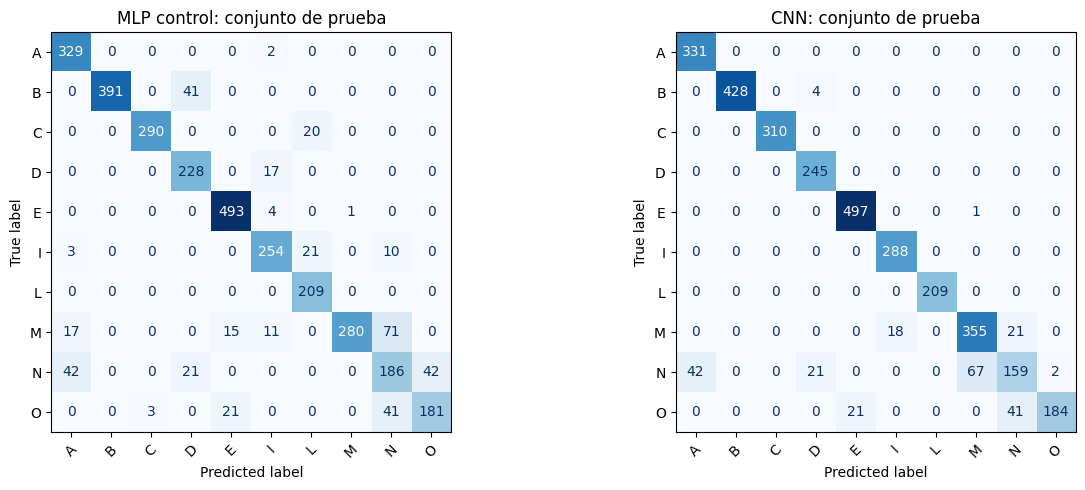

In [ ]:
from sklearn.metrics import accuracy_score

def evaluate_model(candidate, model_name):
    t0 = time.perf_counter()
    probabilities = candidate.predict(X_test, verbose=0)
    inference_seconds = time.perf_counter() - t0
    predictions = probabilities.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, predictions, average='macro', zero_division=0)
    metrics = {
        'Modelo': model_name,
        'Accuracy test': accuracy_score(y_test, predictions),
        'Precision macro': precision,
        'Recall macro': recall,
        'F1 macro': f1,
        'Parámetros': candidate.count_params(),
        'Tiempo entrenamiento (s)': mlp_train_seconds if model_name == 'MLP control' else cnn_train_seconds,
        'Inferencia (ms/imagen)': 1000 * inference_seconds / len(X_test)
    }
    return metrics, probabilities, predictions

mlp_metrics, mlp_prob, mlp_pred = evaluate_model(mlp_model, 'MLP control')
cnn_metrics, y_prob, y_pred = evaluate_model(model, 'CNN')
print('MLP control')
print(classification_report(y_test, mlp_pred, target_names=CLASS_NAMES, zero_division=0))
print('CNN')
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, zero_division=0))

fig, axes = plt.subplots(1,2,figsize=(13,5))
for ax, pred, title in [(axes[0], mlp_pred, 'MLP control'), (axes[1], y_pred, 'CNN')]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=CLASS_NAMES).plot(
        ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
    ax.set_title(f'{title}: conjunto de prueba')
plt.tight_layout(); plt.savefig('outputs/matrices_confusion_mlp_cnn.png', dpi=160); plt.show()


## 5. Comparación entre MLP y CNN

La tabla resume la comparación controlada con los resultados generados en esta ejecución. Las cifras históricas del MLP de la Evaluación 1 se muestran aparte como contexto, porque su configuración de entrenamiento no coincide con el control reentrenado aquí.


In [ ]:
comparison = pd.DataFrame([mlp_metrics, cnn_metrics])
display(comparison)
comparison.to_csv('outputs/comparacion_mlp_cnn.csv', index=False)

# Resultado histórico informado en el reporte de métricas de la E1.
mlp_e1_reference = pd.DataFrame([{
    'Métrica histórica E1': 'Accuracy test 89,77%; Precision macro 88,90%; Recall macro 88,81%; F1 macro 0,8854',
    'Parámetros totales': 101770,
    'Nota': 'Referencia del reporte outputs/reporte_metricas.txt; protocolo de entrenamiento anterior.'
}])
display(mlp_e1_reference)


,Modelo,Accuracy test,Precision macro,Recall macro,F1 macro,Parámetros,Tiempo entrenamiento (s),Inferencia (ms/imagen)
0,MLP control,0.875771,0.867929,0.872266,0.865095,101770,7.229132,0.218403
1,CNN,0.926634,0.924339,0.918411,0.917717,693962,54.722062,0.336365


,Métrica histórica E1,Parámetros totales,Nota
0,"Accuracy test 89,77%; Precision macro 88,90%; ...",101770,Referencia del reporte outputs/reporte_metrica...


### Lectura de la comparación

La comparación principal es entre `MLP control` y `CNN`: mismo split, número de épocas, batch size, optimizador, función de pérdida y conjunto de prueba. El MLP trabaja con los píxeles aplanados; la CNN conserva estructura espacial y reutiliza filtros convolucionales. Comentar las diferencias de métricas, parámetros, tiempo y errores que aparezcan al ejecutar el notebook. La fila histórica E1 es solo contexto, no una comparación con condiciones idénticas.


## 6. Ejemplos correctos e incorrectos

Se presentan ejemplos predichos por cada modelo para inspeccionar sus aciertos y errores sobre el mismo test.


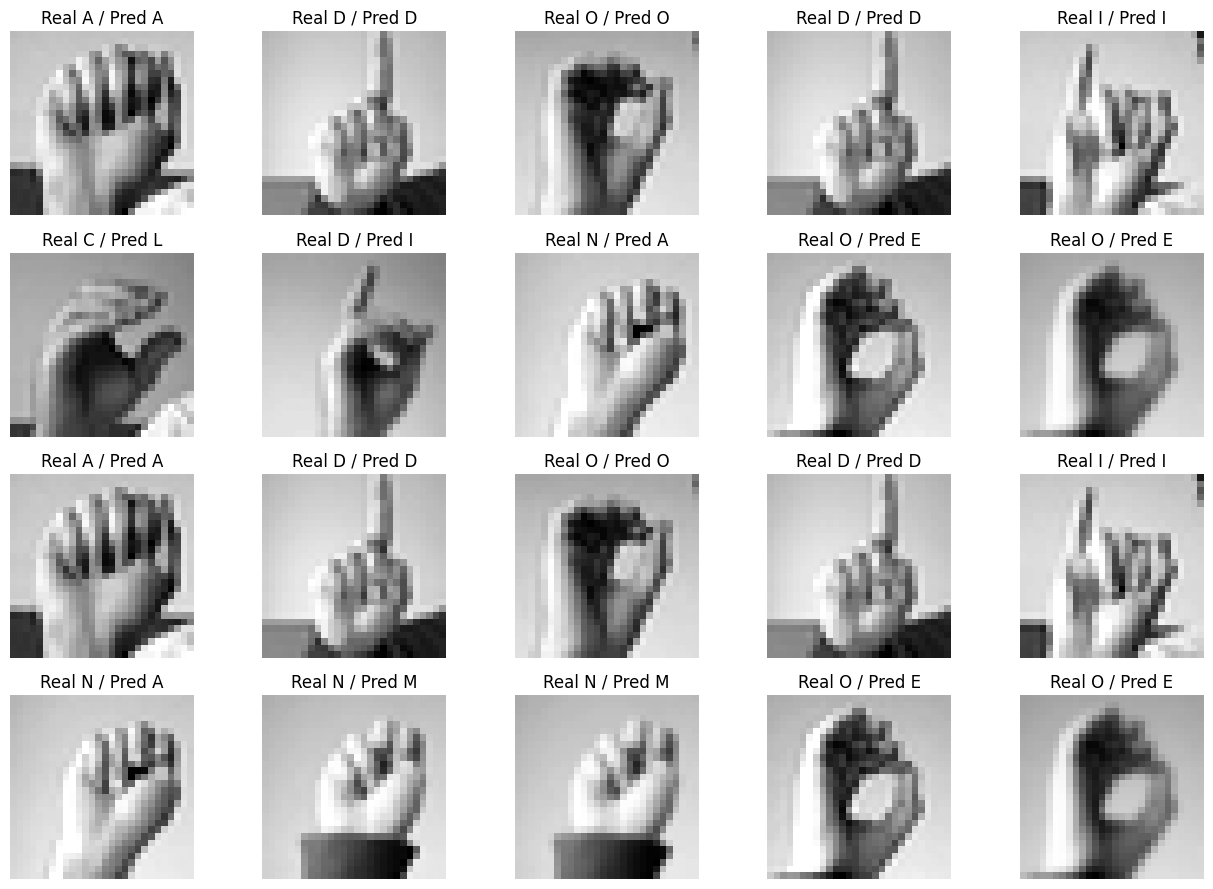

In [ ]:
fig, axes = plt.subplots(4,5,figsize=(13,9))
for row, (name, pred) in enumerate([('MLP correctas',mlp_pred),('MLP errores',mlp_pred),
                                    ('CNN correctas',y_pred),('CNN errores',y_pred)]):
    indices = np.flatnonzero(y_test == pred) if 'correctas' in name else np.flatnonzero(y_test != pred)
    for col in range(5):
        ax=axes[row,col]
        if col < len(indices):
            i=indices[col]
            ax.imshow(X_test[i,:,:,0], cmap='gray')
            ax.set_title(f'Real {CLASS_NAMES[y_test[i]]} / Pred {CLASS_NAMES[pred[i]]}')
        ax.axis('off')
    axes[row,0].set_ylabel(name)
plt.tight_layout(); plt.savefig('outputs/ejemplos_mlp_cnn.png', dpi=160); plt.show()


## 7. Mapas de características y mapa de activación

Se visualizan los mapas de la capa convolucional de la CNN y se calcula Grad-CAM para una muestra por clase. La visualización es cualitativa; debe comentarse qué zonas de la mano resaltan y cómo se relacionan con la predicción, sin tratarlo como una explicación causal.


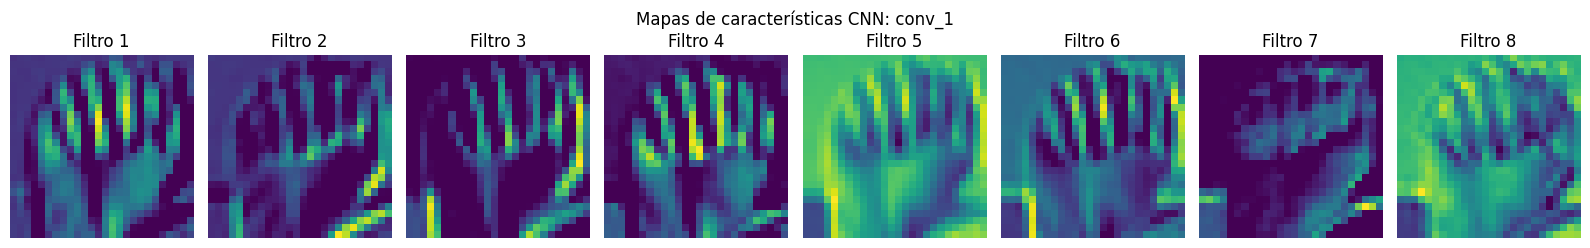

In [ ]:
# Mapas de características de la capa convolucional
feature_model = tf.keras.Model(inputs=model.inputs, outputs=model.get_layer('conv_1').output)
feature_maps = feature_model.predict(X_test[:1], verbose=0)
count = min(8, feature_maps.shape[-1])
fig, axes = plt.subplots(1,count,figsize=(2*count,2.5))
for i, ax in enumerate(np.atleast_1d(axes)):
    ax.imshow(feature_maps[0,:,:,i], cmap='viridis'); ax.set_title(f'Filtro {i+1}'); ax.axis('off')
fig.suptitle('Mapas de características CNN: conv_1')
plt.tight_layout(); plt.savefig('outputs/feature_maps_conv1.png', dpi=160); plt.show()

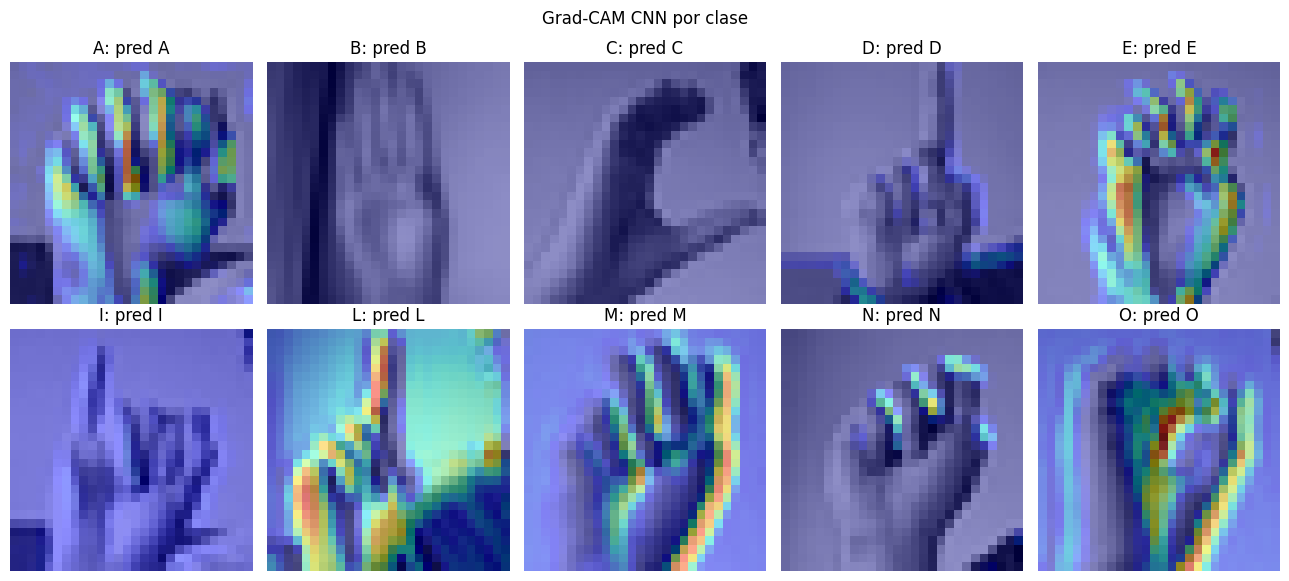

In [ ]:
import warnings
# Grad-CAM: una imagen representante por cada clase
last_conv = model.get_layer('conv_1')

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    grad_model = tf.keras.Model(inputs=model.inputs, outputs=[last_conv.output, model.outputs[0]])

fig, axes = plt.subplots(2,5,figsize=(13,6))
for class_id, name in enumerate(CLASS_NAMES):
    idx = int(np.flatnonzero(y_test == class_id)[0])
    image = X_test[idx:idx+1]
    with tf.GradientTape() as tape:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            conv_out, pred = grad_model(image, training=False)
        class_score = pred[:, class_id]
    grads = tape.gradient(class_score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1,2), keepdims=True)
    cam = tf.reduce_sum(weights * conv_out, axis=-1)[0]
    cam = tf.maximum(cam, 0)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[...,None], (28,28)).numpy().squeeze()
    ax = axes.flat[class_id]
    ax.imshow(image[0,:,:,0], cmap='gray')
    ax.imshow(cam, cmap='jet', alpha=.45, vmin=0, vmax=1)
    ax.set_title(f'{name}: pred {CLASS_NAMES[int(pred.numpy().argmax())]}'); ax.axis('off')
plt.suptitle('Grad-CAM CNN por clase')
plt.tight_layout(); plt.savefig('outputs/cnn_gradcam_por_clase.png', dpi=160); plt.show()

## 8. Conclusiones

En esta comparación, la CNN obtuvo un mejor desempeño en el conjunto de prueba que el MLP de control, bajo la misma partición de datos, las mismas diez épocas y el mismo tamaño de lote. La CNN alcanzó 92,66% de accuracy y 0,9177 de F1 macro, frente a 87,58% y 0,8651 del MLP. Esto equivale a una diferencia de 5,09 puntos porcentuales en accuracy y 5,26 puntos en F1 macro. En términos de errores, el MLP clasificó incorrectamente 403 de 3.244 imágenes, mientras que la CNN se equivocó en 238.
La mejora de desempeño tuvo un costo en este experimento: la CNN contó con 693.962 parámetros, aproximadamente 6,8 veces los 101.770 del MLP, y su tiempo de entrenamiento medido fue 54,72 s frente a 7,23 s. La latencia de inferencia también fue algo mayor para la CNN (0,336 ms por imagen frente a 0,218 ms). Por ello, la CNN fue más precisa en esta prueba, pero requirió más recursos en la configuración evaluada.
La clase N siguió siendo la más difícil para ambos modelos. Su recall fue 55% con la CNN y 64% con el MLP, lo que muestra que parte de las señas visualmente parecidas continúa siendo ambigua incluso con convoluciones. En cambio, la CNN mejoró claramente el reconocimiento de varias clases, como I y O, y alcanzó F1 de 1,00 en B, C y L.
Aunque las accuracies de validación llegaron a 100% para la CNN y 98,44% para el MLP, los resultados en test fueron inferiores, especialmente para el MLP. Esta diferencia entre validación y prueba aconseja interpretar la capacidad de generalización con cautela. En conjunto, los resultados de esta ejecución favorecen a la CNN en métricas de prueba; no obstante, la conclusión se limita a esta variante de diez clases, esta partición y estas arquitecturas. Los mapas de características y Grad-CAM complementan la comparación al mostrar activaciones de la CNN, pero deben interpretarse como visualizaciones cualitativas.
